# embedding with PatentBERTa

In [5]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('AI-Growth-Lab/PatentSBERTa')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

# data

In [8]:
import pandas as pd
llm = pd.read_csv('/llm_without_chunks.csv')

In [9]:
llm

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,their_score_planning,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.923894,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.007498,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.530319,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.999981,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.001134,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.000004,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000116,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000207,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003473,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
patent_numbers = list(llm['patent_id'])

In [11]:
patent_numbers

[5376962,
 6625588,
 5568413,
 9760850,
 6611826,
 4961002,
 6678670,
 5812698,
 5677995,
 8892487,
 8880999,
 5261037,
 5663626,
 5293459,
 9691019,
 9037472,
 9600471,
 8321417,
 6041322,
 9714885,
 9646194,
 7818275,
 9836527,
 5579484,
 9087302,
 6856957,
 6016384,
 5113482,
 5598076,
 10078630,
 4874963,
 8676734,
 5581660,
 5245695,
 9747896,
 9727699,
 8630844,
 5799291,
 9349092,
 8543375,
 8249869,
 9977997,
 6952665,
 8805759,
 6983240,
 9542669,
 9123022,
 5473730,
 5365472,
 8589866,
 6311114,
 7620202,
 8554707,
 8768871,
 8650027,
 9286291,
 7454326,
 5027182,
 6003020,
 6622119,
 8311310,
 7409410,
 5706193,
 7349888,
 8682812,
 7352918,
 5806055,
 8646085,
 5761381,
 6018732,
 7814039,
 5517600,
 8812418,
 9922026,
 8250010,
 8798965,
 6208981,
 9785889,
 9324024,
 7684975,
 5761637,
 9135055,
 8494838,
 9792197,
 8639507,
 7076611,
 10083523,
 6510354,
 6338033,
 5450526,
 5568379,
 8873833,
 5832181,
 5432868,
 5390136,
 8582866,
 5235672,
 8515733,
 5675712,
 8918312

In [12]:
patent_texts = list(llm['patent_text'])

In [13]:
patent_texts

['"BACKGROUND OF THE INVENTION The present invention concerns apparatus and a method for processing video signals to implement a plurality of signal processing functions in a single operation, and in particular to apparatus which uses a neural network to perform these functions. In many signal processing systems, functions are applied to data sequentially. That is to say one function is applied to the input data and the output values produced by that function are applied as the input values to the next function. This type of processing is commonly referred to as pipeline processing. An exemplary system which employs pipeline processing is a video camera. One such camera is described in an article by K. A. Parulski et al. entitled ""A Digital Color CCD Imaging System Using Custom VLSI Circuits,"" IEEE Transactions on Consumer Electronics, Vol. 35, No. 3, pp. 382-389, August, 1989. The camera described in this paper employs a CCD sensor which collects samples representing successive vide

## Read keywords

In [14]:
with open("/keywords3-new.txt", "r", encoding='utf8') as F:
    lines = F.readlines()
lines = list(lines)
for i in range(len(lines)):
    lines[i] = lines[i][:-1]
lines = " ".join(lines)

In [15]:
keywords = lines
keywords

'human action action recognition recognition activity recognition activity human activity  adaboost  adaptive boosting adaptive boosting adversarial network adversarial network generative adversarial generative adversarial network ant colony colony colony optimisation optimisation artificial intelligence  intelligence  artificial human aware aware aware artificial association rule association  autoencoder   autonomous autonomous vehicle  autonomous weapon backpropagation  Bayesian learning Bayesian bee colony   artificial bee colony algorithm algorithm Bayesian signal blind signal signal separation bootstrap aggregation aggregation bootstrap brownboost  chatbot   classification tree  classification cluster analysis  cluster analysis  cognitive automation cognitive automation cognitive computing computing cognitive modelling   modelling collaborative filtering  filtering collaborative  collision avoidance  avoidance  collision computational intelligence   computational pathology  comput

# Bert model

In [16]:
combined_keywords_embedding = model.encode(keywords, convert_to_tensor=True)
patent_embeddings = model.encode(patent_texts, convert_to_tensor=True)

In [17]:
from sentence_transformers.util import cos_sim
similarity_scores = cos_sim(combined_keywords_embedding, patent_embeddings)

In [20]:
import numpy as np
similarity_scores = list(similarity_scores[0].cpu().numpy())

# makes similarity data

In [21]:
data = {'patent_number': patent_numbers, 'similarity': similarity_scores}
bert_similarities = pd.DataFrame(data=data)
bert_similarities
bert_similarities.to_csv('/bert_similaritiesof_patents.csv', index=False)

In [22]:
bert_similarities

,patent_number,similarity
0,5376962,0.353272
1,6625588,0.371152
2,5568413,0.421729
3,9760850,0.450692
4,6611826,0.410082
...,...,...
914,7049683,0.265869
915,8604845,0.367049
916,7494582,0.312097
917,6112281,0.361288


# Merge and Prepare data

In [23]:

llm['bert'] = similarity_scores
llm

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning,bert
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.353272
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.371152
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.421729
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.450692
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.410082
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.265869
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.367049
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.312097
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.361288


In [24]:
llm['binary'] = (llm['overall_ai_score'] >= 0.6).astype(int)

## plot ROC curve

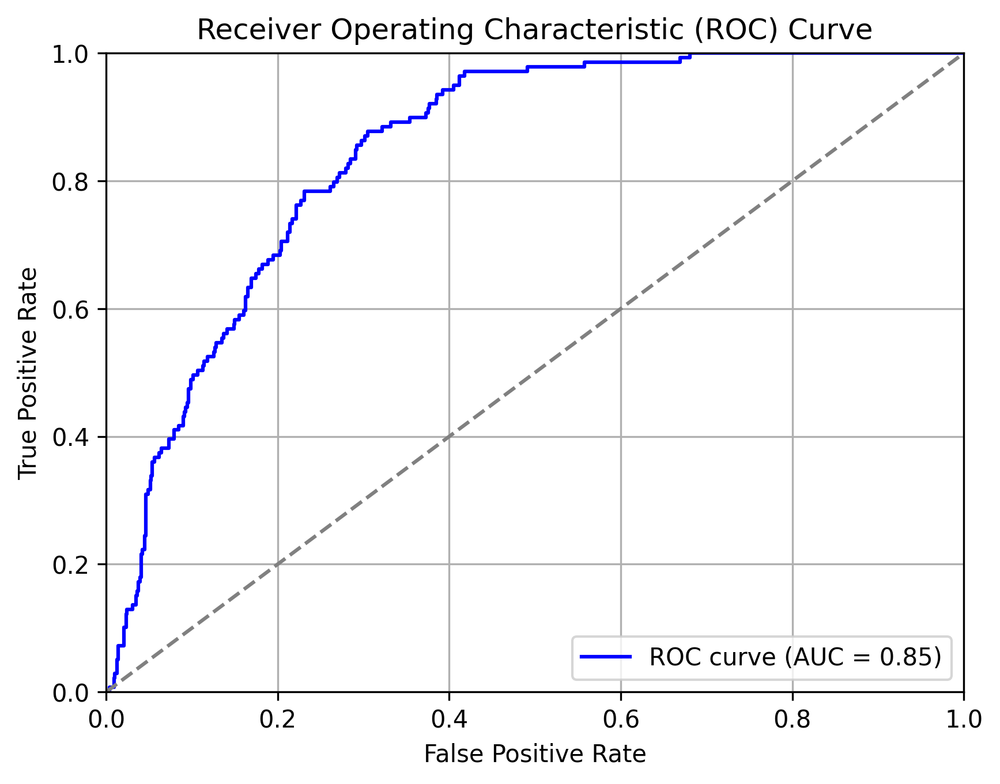

In [26]:
import pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Assuming your CSV file is in the same format as shown in the screenshot
# Replace 'your_file.csv' with your actual file path


# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(llm['binary'], llm['bert'])
roc_auc = roc_auc_score(llm['binary'], llm['bert'])

# Plotting the ROC curve
plt.figure(dpi=300)
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig('/roc_curve_high_res_seed_phrase_data_v3_bert_score.png', dpi=300, bbox_inches='tight')  # Save with high resolution
plt.show()


# Find threshold

In [31]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

precision_list = []
recall_list = []
accuracy_list = []
f1_list = []
threshold_list = []

threshold = 0.38
while threshold <= 0.4:
    llm['similarity_binary'] = (llm['bert'] >= threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = llm['binary']
    y_pred = llm['similarity_binary']
    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    threshold_list.append(threshold)
    precision_list.append(precision)
    recall_list.append(recall)
    accuracy_list.append(accuracy)
    f1_list.append(f1)
    threshold = threshold + 0.001


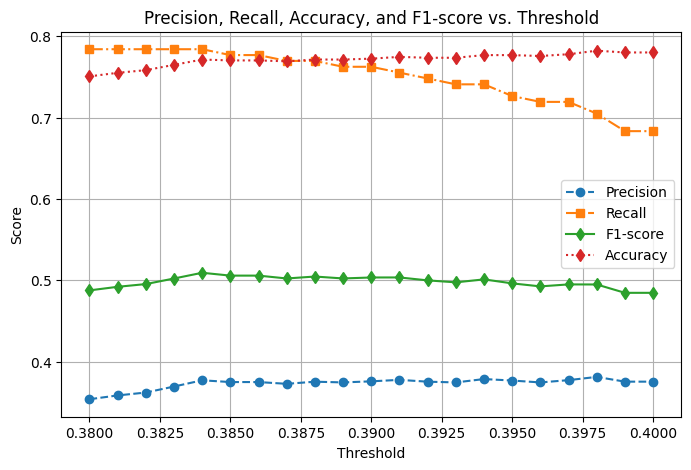

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Plot
plt.figure(figsize=(8, 5))
plt.plot(threshold_list, precision_list, marker='o', label='Precision', linestyle='--')
plt.plot(threshold_list, recall_list, marker='s', label='Recall', linestyle='-.')
plt.plot(threshold_list, f1_list, marker='d', label='F1-score', linestyle='-')
plt.plot(threshold_list, accuracy_list, marker='d', label='Accuracy', linestyle=':')

# Labels and title
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, Accuracy, and F1-score vs. Threshold")
plt.legend()
plt.grid(True)

# Save the plot
plt.savefig("/threshold_seed_plot_v5_bert_score.png", dpi=300)  # Save as PNG (or change to .jpg, .pdf, etc.)

# Show plot
plt.show()


In [34]:
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

threshold = 0.384
print(f'threshold: {threshold}')
llm['similarity_binary'] = (llm['bert'] >= threshold).astype(int)

# Assuming your 'predict' column contains the true values
y_true = llm['binary']
y_pred = llm['similarity_binary']

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Calculate precision, recall, accuracy, and F1 score
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print the results
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"Accuracy: {accuracy}")
print(f"F1 Score: {f1}")

threshold: 0.384
Confusion Matrix:
[[600 180]
 [ 30 109]]
Precision: 0.3771626297577855
Recall: 0.7841726618705036
Accuracy: 0.7714907508161044
F1 Score: 0.5093457943925234


# Confusion Matrix

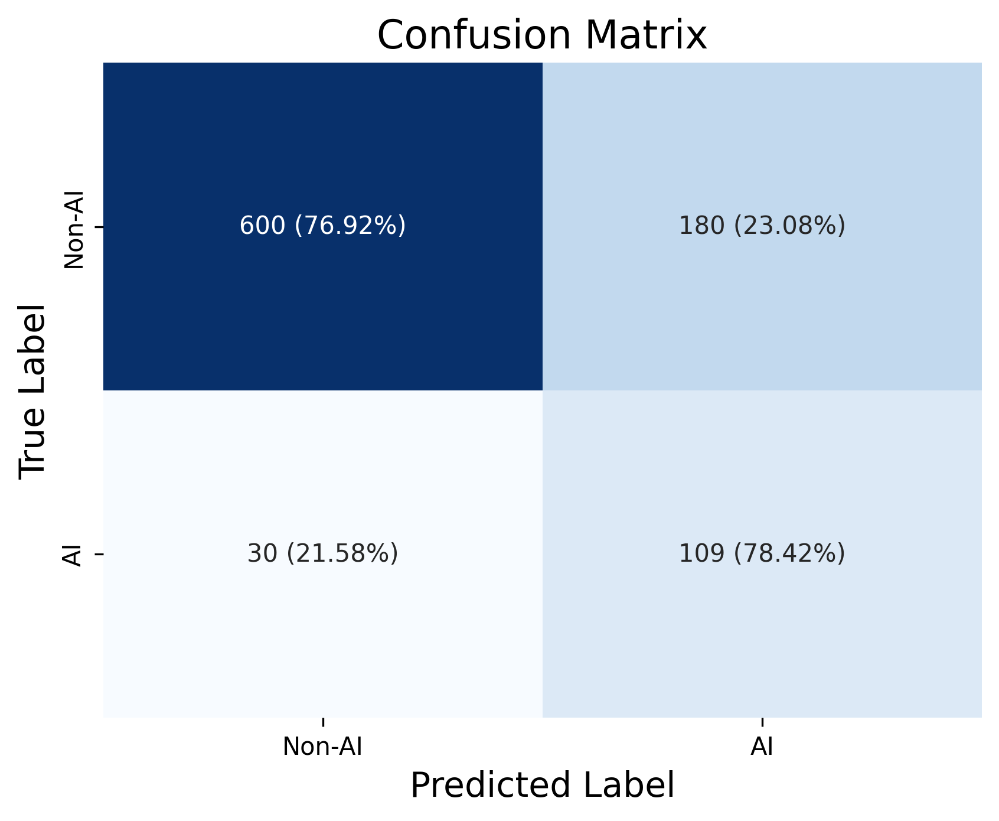

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calculate the row-wise percentage of data in each cell
conf_matrix_percent = conf_matrix / conf_matrix.sum(axis=1, keepdims=True) * 100

# Create labels that show both the count and row-wise percentage for each cell
labels = np.asarray([f'{count} ({percent:.2f}%)' for count, percent in zip(conf_matrix.flatten(), conf_matrix_percent.flatten())])
labels = labels.reshape(conf_matrix.shape)

# Plot confusion matrix
plt.figure(dpi=300)
sns.heatmap(conf_matrix, annot=labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Non-AI', 'AI'], yticklabels=['Non-AI', 'AI'])

plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.title('Confusion Matrix', fontsize=16)

# Save the confusion matrix plot
plt.savefig('/confusion_matrix_high_res_seed_phrases_data_v3_bert_score.png', dpi=300, bbox_inches='tight')  # Save with high resolution
plt.show()


# patentsberta chuncking

In [1]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm

class LongContextPatentSBERT:
    def __init__(self, model_name="AI-Growth-Lab/PatentSBERTa", chunk_size=512, overlap=128, device_map="cuda"):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name).to(device_map)
        self.chunk_size = chunk_size
        self.overlap = overlap
        self.device_map = device_map
        self.model.eval()

    def _mean_pool(self, last_hidden_state, attention_mask=None):
        """Mean pooling over sequence dimension."""
        if attention_mask is None:
            return last_hidden_state.mean(dim=1)
        mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
        summed = torch.sum(last_hidden_state * mask, dim=1)
        counts = torch.clamp(mask.sum(dim=1), min=1e-9)
        return summed / counts

    def encode_batch(self, texts, batch_size=32):
        """Encode a list of texts with long-context chunking + mean pooling."""
        embeddings = []
        for i in tqdm(range(0, len(texts), batch_size), desc="Encoding"):
            batch = texts[i:i+batch_size]
            # Tokenize without truncation to preserve full text
            inputs = self.tokenizer(batch, return_tensors="pt", padding=True, truncation=False)
            input_ids = inputs["input_ids"].to(self.device_map)
            attention_mask = inputs["attention_mask"].to(self.device_map)

            batch_embeddings = []
            for seq_ids, seq_mask in zip(input_ids, attention_mask):
                valid_len = seq_mask.sum().item()
                if valid_len <= self.chunk_size:
                    # Short doc: encode directly
                    with torch.no_grad():
                        out = self.model(seq_ids.unsqueeze(0), attention_mask=seq_mask.unsqueeze(0))
                    emb = self._mean_pool(out.last_hidden_state, seq_mask.unsqueeze(0))
                else:
                    # Long doc: chunking
                    chunks = []
                    start = 0
                    while start < valid_len:
                        end = min(start + self.chunk_size, valid_len)
                        chunk_ids = seq_ids[start:end]
                        chunk_mask = seq_mask[start:end]
                        chunks.append((chunk_ids.unsqueeze(0), chunk_mask.unsqueeze(0)))
                        start += self.chunk_size - self.overlap

                    chunk_embs = []
                    for c_ids, c_mask in chunks:
                        with torch.no_grad():
                            out = self.model(c_ids, attention_mask=c_mask)
                        chunk_embs.append(self._mean_pool(out.last_hidden_state, c_mask))
                    emb = torch.mean(torch.stack(chunk_embs), dim=0)

                # L2 normalize
                emb = emb / (torch.norm(emb) + 1e-8)
                # FIX: Squeeze to remove batch dimension and convert to numpy
                batch_embeddings.append(emb.squeeze().cpu().numpy())

            embeddings.extend(batch_embeddings)
        return np.array(embeddings)  # Return as numpy array

    def cosine_similarity(self, vec1, vec2):
        """Compute cosine similarity between two 1D arrays."""
        # FIX: Ensure vectors are 1D
        vec1 = np.array(vec1).flatten()
        vec2 = np.array(vec2).flatten()
        
        n1, n2 = np.linalg.norm(vec1), np.linalg.norm(vec2)
        if n1 > 0 and n2 > 0:
            return np.dot(vec1, vec2) / (n1 * n2 + 1e-8)
        return 0.0



In [2]:
with open("D:\\New-patents\\Landscaping\\data\\keywords3-new.txt", "r", encoding='utf8') as F:
    lines = F.readlines()
lines = list(lines)
for i in range(len(lines)):
    lines[i] = lines[i][:-1]
lines = " ".join(lines)

In [3]:
keywords = lines
keywords

'human action action recognition recognition activity recognition activity human activity  adaboost  adaptive boosting adaptive boosting adversarial network adversarial network generative adversarial generative adversarial network ant colony colony colony optimisation optimisation artificial intelligence  intelligence  artificial human aware aware aware artificial association rule association  autoencoder   autonomous autonomous vehicle  autonomous weapon backpropagation  Bayesian learning Bayesian bee colony   artificial bee colony algorithm algorithm Bayesian signal blind signal signal separation bootstrap aggregation aggregation bootstrap brownboost  chatbot   classification tree  classification cluster analysis  cluster analysis  cognitive automation cognitive automation cognitive computing computing cognitive modelling   modelling collaborative filtering  filtering collaborative  collision avoidance  avoidance  collision computational intelligence   computational pathology  comput

In [4]:
import pandas as pd
llm = pd.read_csv('./data/llm_without_chunks.csv')

In [5]:
patent_numbers = list(llm['patent_id'])

In [6]:
patent_texts = list(llm['patent_text'])

In [7]:
encoder = LongContextPatentSBERT(model_name="AI-Growth-Lab/PatentSBERTa", chunk_size=512, overlap=128)

# Encode patents & AI keyword description
patent_embeddings = encoder.encode_batch(patent_texts, batch_size=64)
ai_kw_embedding = encoder.encode_batch([keywords])[0]

# Compute relevance scores
ai_scores = [encoder.cosine_similarity(p, ai_kw_embedding) for p in patent_embeddings]


Encoding: 100%|██████████| 1/1 [00:00<00:00, 12.20it/s]


In [8]:
len(ai_scores)

919

In [9]:

llm['bert'] = ai_scores
llm

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning,bert
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.582900
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.549589
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.546569
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.630345
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.541708
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.413379
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.476053
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.486510
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.530930


## Evaluation

In [10]:
llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)

In [15]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
precision_list = []
recall_list = []
accuracy_list = []
f1_list = []
threshold_list = []

threshold = 0.55
while threshold <= 0.57:
    llm['similarity_binary'] = (llm['bert'] >= threshold).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['similarity_binary'], test_size=0.3, random_state=4)
    # Assuming your 'predict' column contains the true values
    y_true = y_true_val
    y_pred = y_scores_val
    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    threshold_list.append(threshold)
    precision_list.append(precision)
    recall_list.append(recall)
    accuracy_list.append(accuracy)
    f1_list.append(f1)
    threshold = threshold + 0.001


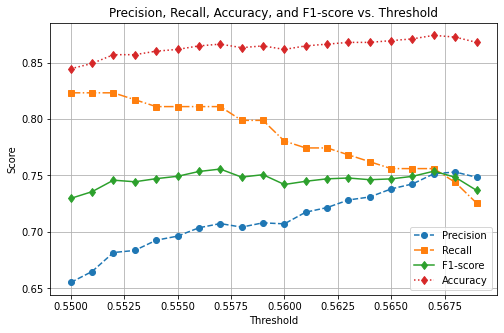

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Plot
plt.figure(figsize=(8, 5))
plt.plot(threshold_list, precision_list, marker='o', label='Precision', linestyle='--')
plt.plot(threshold_list, recall_list, marker='s', label='Recall', linestyle='-.')
plt.plot(threshold_list, f1_list, marker='d', label='F1-score', linestyle='-')
plt.plot(threshold_list, accuracy_list, marker='d', label='Accuracy', linestyle=':')

# Labels and title
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, Accuracy, and F1-score vs. Threshold")
plt.legend()
plt.grid(True)

# Save the plot
# plt.savefig("/threshold_seed_plot_v5_bert_score.png", dpi=300)  # Save as PNG (or change to .jpg, .pdf, etc.)

# Show plot
plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

threshold = 0.557
print(f'threshold: {threshold}')
llm['similarity_binary'] = (llm['bert'] >= threshold).astype(int)
y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['similarity_binary'], test_size=0.3, random_state=4)
# Assuming your 'predict' column contains the true values
y_true = y_true_test
y_pred = y_scores_test

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Calculate precision, recall, accuracy, and F1 score
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print the results
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"Accuracy: {accuracy}") 
print(f"F1 Score: {f1}")

threshold: 0.557
Confusion Matrix:
[[188  24]
 [ 17  47]]
Precision: 0.6619718309859155
Recall: 0.734375
Accuracy: 0.8514492753623188
F1 Score: 0.6962962962962963
